# AIM : 

To develop and compare multiple machine learning algorithms for predicting loan default risk using historical borrower data.

To evaluate model performance using appropriate classification metrics and identify the most effective model for accurate loan default prediction.

# EDA

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("loan_default_dataset.csv")

df.head()


,Loan_ID,Customer_ID,Age,Employment_Type,Employment_Years,Education,Dependents,Annual_Income,Monthly_Income,Existing_Loan_Amount,...,Loan_Term_Months,Interest_Rate,Loan_Purpose,Collateral_Value,Previous_Loan_Count,Previous_Defaults,Late_Payments_12M,Credit_Card_Utilization,Credit_History_Years,Loan_Default
0,LN113916,CUST213916,53,SALARIED,11.0,Graduate,1.0,579000.0,48250,0,...,60,11.65,Education,0.0,1,0,0,0.16,5,0
1,LN109534,CUST209534,36,Contract,11.0,Graduate,0.0,708000.0,59000,0,...,300,8.75,Home,2895000.0,1,0,0,0.28,9,0
2,LN101359,CUST201359,43,Unemployed,0.0,Graduate,2.0,116600.0,9717,109500,...,36,15.35,Business,0.0,1,1,1,0.42,1,1
3,LN114956,CUST214956,64,Salaried,10.0,Post-Graduate,0.0,974400.0,81200,0,...,36,11.33,Personal,NaN,0,0,1,0.37,7,0
4,LN112181,CUST212181,45,Salaried,7.0,Post-Graduate,2.0,1020900.0,85075,394600,...,36,11.51,Personal,0.0,3,0,2,0.66,18,0


In [4]:
# Dataset dimensions
df.shape

(20045, 25)

In [5]:
# Column names
df.columns

Index(['Loan_ID', 'Customer_ID', 'Age', 'Employment_Type', 'Employment_Years',
       'Education', 'Dependents', 'Annual_Income', 'Monthly_Income',
       'Existing_Loan_Amount', 'Existing_EMI', 'Credit_Score',
       'Savings_Balance', 'Debt_to_Income_Ratio', 'Loan_Amount',
       'Loan_Term_Months', 'Interest_Rate', 'Loan_Purpose', 'Collateral_Value',
       'Previous_Loan_Count', 'Previous_Defaults', 'Late_Payments_12M',
       'Credit_Card_Utilization', 'Credit_History_Years', 'Loan_Default'],
      dtype='object')

In [6]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20045 entries, 0 to 20044
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Loan_ID                  20045 non-null  object 
 1   Customer_ID              20045 non-null  object 
 2   Age                      20045 non-null  int64  
 3   Employment_Type          20045 non-null  object 
 4   Employment_Years         19444 non-null  float64
 5   Education                19444 non-null  object 
 6   Dependents               19645 non-null  float64
 7   Annual_Income            19645 non-null  float64
 8   Monthly_Income           20045 non-null  int64  
 9   Existing_Loan_Amount     20045 non-null  int64  
 10  Existing_EMI             20045 non-null  int64  
 11  Credit_Score             19245 non-null  float64
 12  Savings_Balance          19043 non-null  float64
 13  Debt_to_Income_Ratio     19544 non-null  float64
 14  Loan_Amount           

In [7]:
# Statistical summary
df.describe()

,Age,Employment_Years,Dependents,Annual_Income,Monthly_Income,Existing_Loan_Amount,Existing_EMI,Credit_Score,Savings_Balance,Debt_to_Income_Ratio,Loan_Amount,Loan_Term_Months,Interest_Rate,Collateral_Value,Previous_Loan_Count,Previous_Defaults,Late_Payments_12M,Credit_Card_Utilization,Credit_History_Years,Loan_Default
count,20045.000000,19444.000000,19645.000000,1.964500e+04,20045.000000,2.004500e+04,20045.000000,19245.000000,1.904300e+04,19544.000000,2.004500e+04,20045.000000,20045.000000,1.974300e+04,20045.000000,20045.000000,20045.000000,19444.000000,20045.000000,20045.000000
mean,54.064754,6.649815,1.626368,9.259777e+05,77130.875131,2.304307e+05,5780.771464,721.619330,2.121573e+05,0.469715,1.348503e+06,76.565927,11.550238,1.170057e+06,1.455475,0.229833,1.158294,0.410351,7.736243,0.132003
std,9.648290,4.809398,1.332242,7.066996e+05,58903.705629,3.972973e+05,10087.884695,65.190509,3.270603e+05,0.308992,1.710871e+06,70.005962,2.351362,2.287681e+06,1.170581,0.472564,1.202271,0.213256,4.412176,0.338502
min,27.000000,0.000000,0.000000,9.000000e+04,7500.000000,0.000000e+00,0.000000,426.000000,1.700000e+03,0.037000,5.000000e+04,12.000000,7.500000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.000000,3.000000,1.000000,5.240000e+05,43658.000000,0.000000e+00,0.000000,679.000000,5.490000e+04,0.270000,4.160000e+05,36.000000,9.540000,0.000000e+00,1.000000,0.000000,0.000000,0.250000,4.000000,0.000000
50%,54.000000,6.000000,1.000000,7.656000e+05,63792.000000,0.000000e+00,0.000000,724.000000,1.143000e+05,0.409000,7.810000e+05,48.000000,11.830000,0.000000e+00,1.000000,0.000000,1.000000,0.400000,7.000000,0.000000
75%,62.000000,9.000000,2.000000,1.123200e+06,93542.000000,3.520000e+05,8594.000000,767.000000,2.394000e+05,0.582000,1.600000e+06,84.000000,13.420000,1.456000e+06,2.000000,0.000000,2.000000,0.560000,10.000000,0.000000
max,68.000000,42.000000,5.000000,9.000000e+06,750000.000000,8.329400e+06,183433.000000,900.000000,7.115700e+06,3.000000,2.500000e+07,300.000000,18.280000,3.672300e+07,7.000000,4.000000,8.000000,1.000000,40.000000,1.000000


In [8]:
# Check missing values
df.isnull().sum()

Loan_ID                       0
Customer_ID                   0
Age                           0
Employment_Type               0
Employment_Years            601
Education                   601
Dependents                  400
Annual_Income               400
Monthly_Income                0
Existing_Loan_Amount          0
Existing_EMI                  0
Credit_Score                800
Savings_Balance            1002
Debt_to_Income_Ratio        501
Loan_Amount                   0
Loan_Term_Months              0
Interest_Rate                 0
Loan_Purpose                400
Collateral_Value            302
Previous_Loan_Count           0
Previous_Defaults             0
Late_Payments_12M             0
Credit_Card_Utilization     601
Credit_History_Years          0
Loan_Default                  0
dtype: int64

In [9]:
# Check duplicate records
df[df.duplicated()]

,Loan_ID,Customer_ID,Age,Employment_Type,Employment_Years,Education,Dependents,Annual_Income,Monthly_Income,Existing_Loan_Amount,...,Loan_Term_Months,Interest_Rate,Loan_Purpose,Collateral_Value,Previous_Loan_Count,Previous_Defaults,Late_Payments_12M,Credit_Card_Utilization,Credit_History_Years,Loan_Default
1723,LN105653,CUST205653,43,Contract,4.0,Graduate,2.0,322300.0,26858,0,...,48,8.34,Auto,451000.0,0,0,0,0.50,6,0
2277,LN115029,CUST215029,68,Self-Employed,7.0,High School,1.0,472400.0,39367,252600,...,60,9.74,Auto,NaN,2,0,0,0.10,13,0
5084,LN116809,CUST216809,54,Salaried,8.0,Post-Graduate,3.0,2401900.0,200158,0,...,36,13.07,Personal,0.0,1,0,0,0.10,11,0
7641,LN112313,CUST212313,51,Salaried,6.0,Diploma,2.0,667400.0,55617,407700,...,24,12.40,Education,0.0,1,0,1,0.60,10,0
7970,LN104565,CUST204565,44,Self-Employed,3.0,Graduate,3.0,352500.0,29375,0,...,36,16.05,Business,0.0,2,1,2,0.87,11,0
8753,LN104674,CUST204674,59,Salaried,6.0,High School,2.0,522700.0,43558,430700,...,240,8.70,Home,2081000.0,4,0,0,0.17,4,0
9139,LN104786,CUST204786,62,Self-Employed,13.0,Post-Graduate,0.0,961900.0,80158,0,...,180,9.79,Home,4824000.0,1,0,0,0.39,7,0
9320,LN112153,CUST212153,68,Contract,15.0,Post-Graduate,3.0,795300.0,66275,482600,...,48,10.00,Auto,834000.0,6,0,0,0.45,7,0
10498,LN104436,CUST204436,68,Contract,12.0,Post-Graduate,1.0,1240100.0,103342,568700,...,36,12.86,Business,0.0,3,1,2,0.32,5,0
10583,LN114758,CUST214758,47,Salaried,1.0,Graduate,2.0,758200.0,63183,0,...,120,7.50,Home,6228000.0,3,0,1,0.33,5,0


In [10]:
# Remove duplicates
df = df.drop_duplicates()

In [11]:
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (20000, 25)


In [12]:

df['Loan_Default'].value_counts()


Loan_Default
0    17357
1     2643
Name: count, dtype: int64

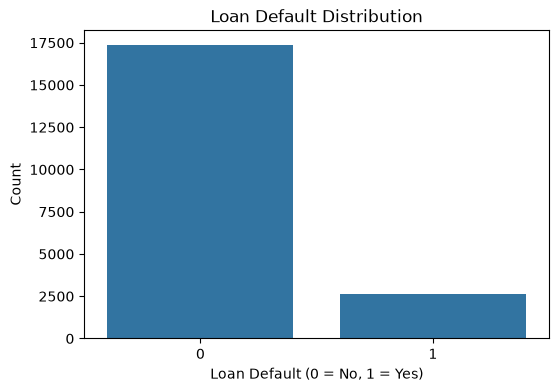

In [13]:

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Loan_Default')

plt.title('Loan Default Distribution')
plt.xlabel('Loan Default (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.show()


In [14]:

df['Loan_Default'].value_counts(normalize=True) * 100


Loan_Default
0    86.785
1    13.215
Name: proportion, dtype: float64

In [15]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Numerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)


Numerical Features:
['Age', 'Employment_Years', 'Dependents', 'Annual_Income', 'Monthly_Income', 'Existing_Loan_Amount', 'Existing_EMI', 'Credit_Score', 'Savings_Balance', 'Debt_to_Income_Ratio', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate', 'Collateral_Value', 'Previous_Loan_Count', 'Previous_Defaults', 'Late_Payments_12M', 'Credit_Card_Utilization', 'Credit_History_Years', 'Loan_Default']

Categorical Features:
['Loan_ID', 'Customer_ID', 'Employment_Type', 'Education', 'Loan_Purpose']



Default Rate by Employment_Type:
Employment_Type
Unemployed       34.843907
Contract         15.634366
business         14.516129
self employed    14.285714
Business         13.393756
Self-Employed    13.338473
Salaried         10.488653
SALARIED          9.178744
Name: Loan_Default, dtype: float64


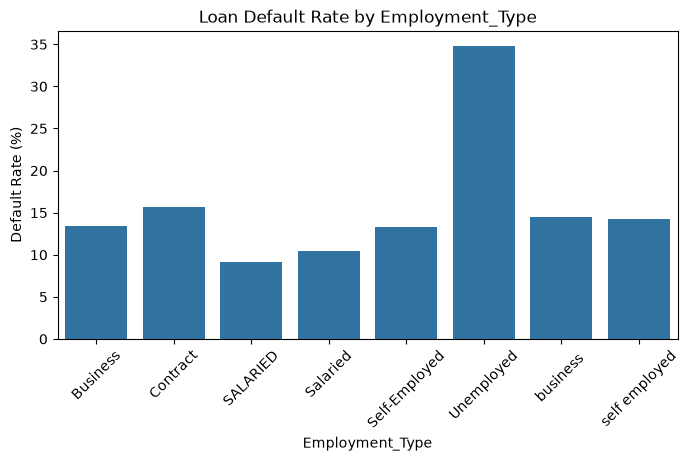


Default Rate by Education:
Education
Post Graduate    17.142857
Diploma          14.086574
High School      13.752013
Graduate         13.661477
graduate         13.142857
Post-Graduate    11.638591
Doctorate        10.773131
Name: Loan_Default, dtype: float64


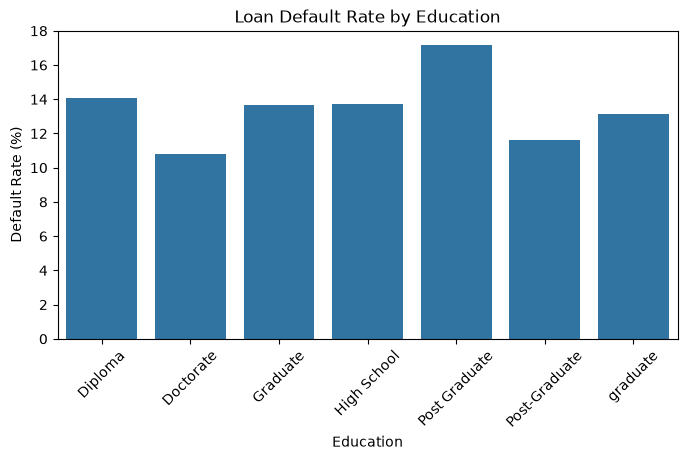


Default Rate by Loan_Purpose:
Loan_Purpose
HOME         21.917808
Business     20.373514
Home         17.668183
Education    11.931581
Auto         11.496581
Personal      9.329878
Medical       8.965517
 Personal     8.139535
Name: Loan_Default, dtype: float64


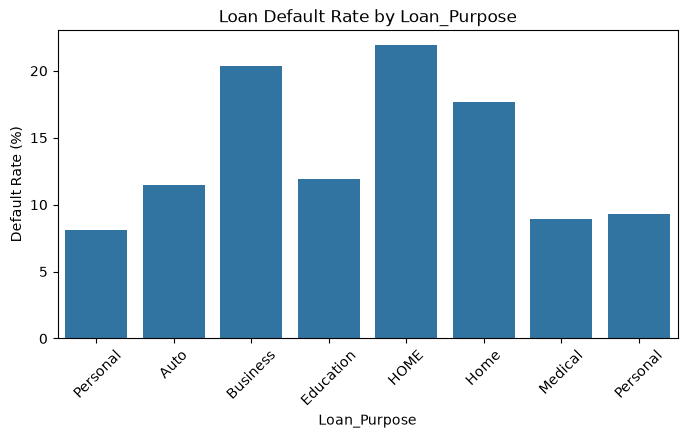

In [18]:

for col in categorical_cols:

    default_rate = df.groupby(col)['Loan_Default'].mean() * 100

    print(f"\nDefault Rate by {col}:")
    print(default_rate.sort_values(ascending=False))

    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=default_rate.index,
        y=default_rate.values
    )

    plt.title(f'Loan Default Rate by {col}')
    plt.ylabel('Default Rate (%)')
    plt.xticks(rotation=45)

    plt.show()


In [19]:
numerical_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ['Loan_Default']
]

# Remove identifier columns if present
numerical_cols = [
    col for col in numerical_cols
    if col not in ['Loan_ID', 'Customer_ID']
]

print("Numerical Predictors:", numerical_cols)

Numerical Predictors: ['Age', 'Employment_Years', 'Dependents', 'Annual_Income', 'Monthly_Income', 'Existing_Loan_Amount', 'Existing_EMI', 'Credit_Score', 'Savings_Balance', 'Debt_to_Income_Ratio', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate', 'Collateral_Value', 'Previous_Loan_Count', 'Previous_Defaults', 'Late_Payments_12M', 'Credit_Card_Utilization', 'Credit_History_Years']


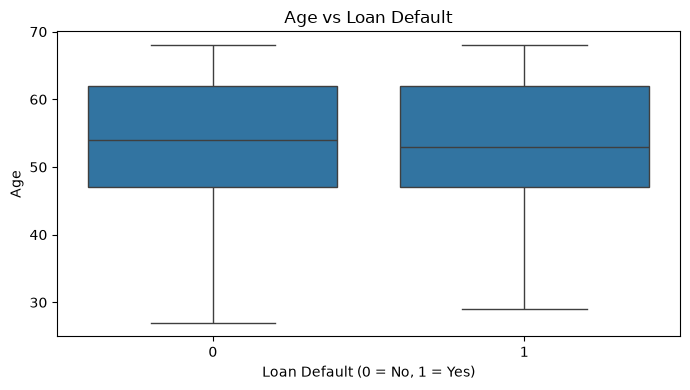

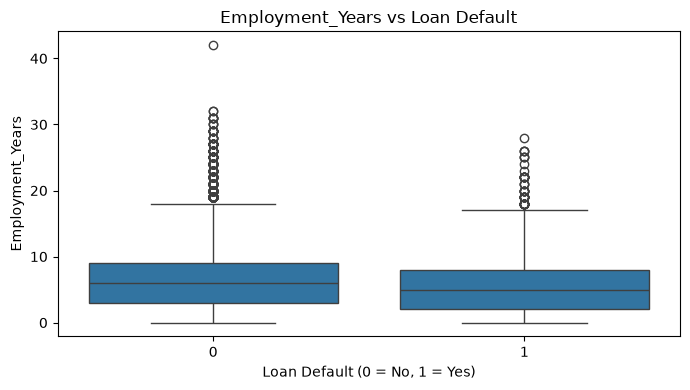

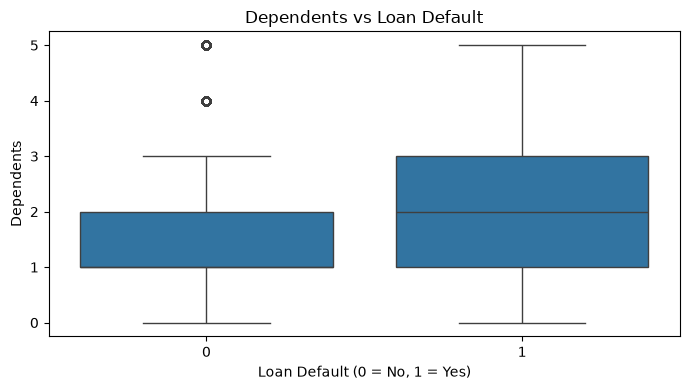

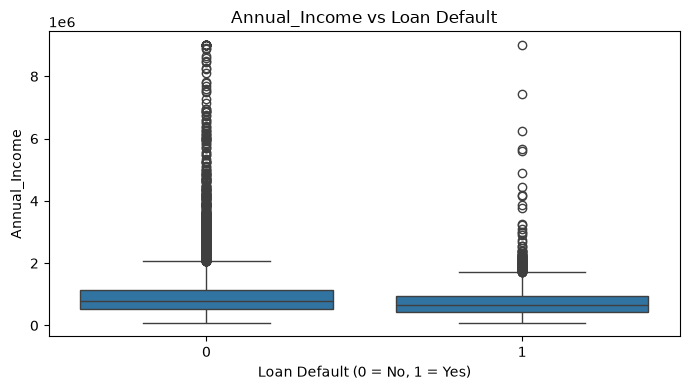

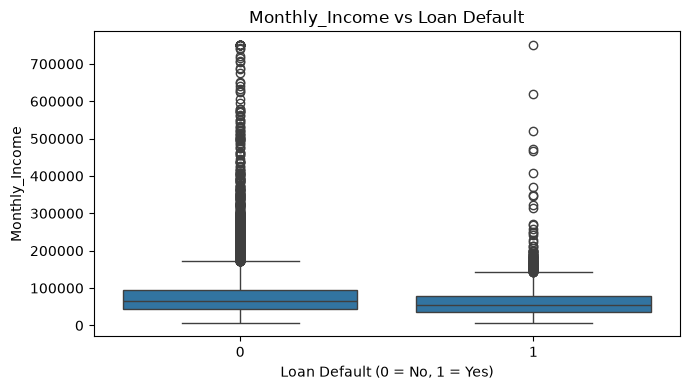

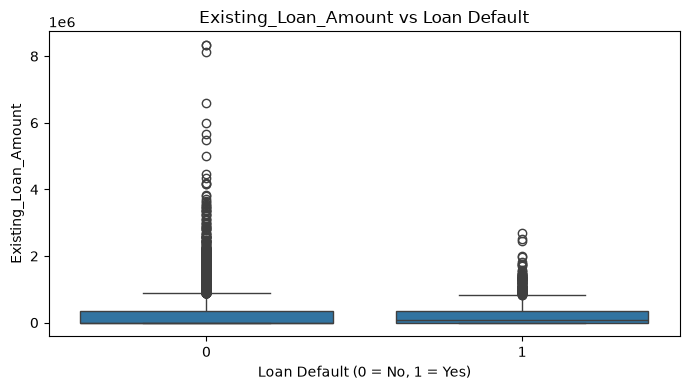

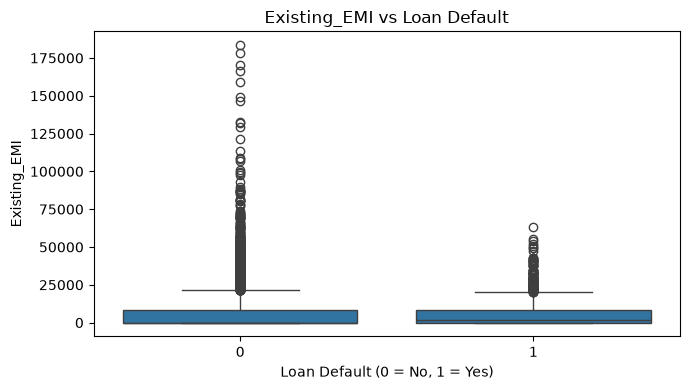

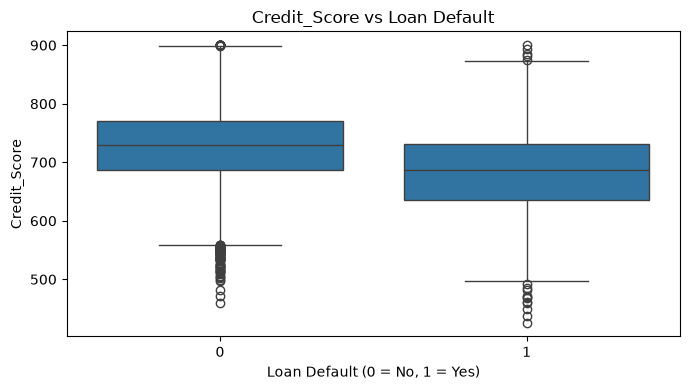

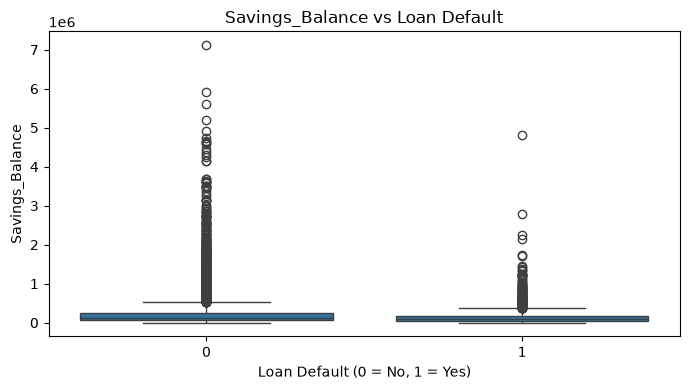

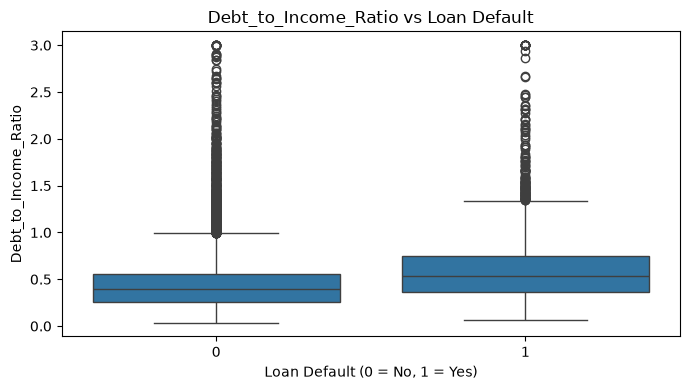

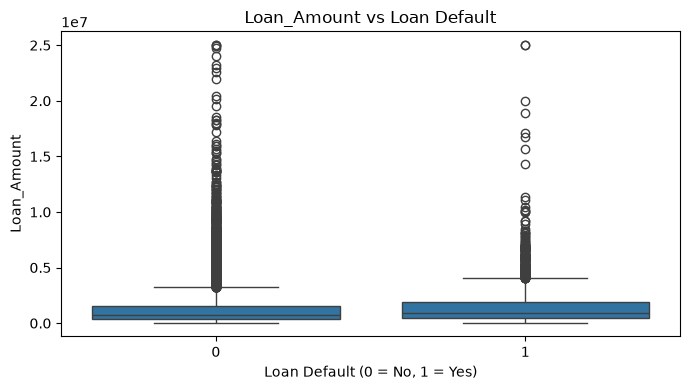

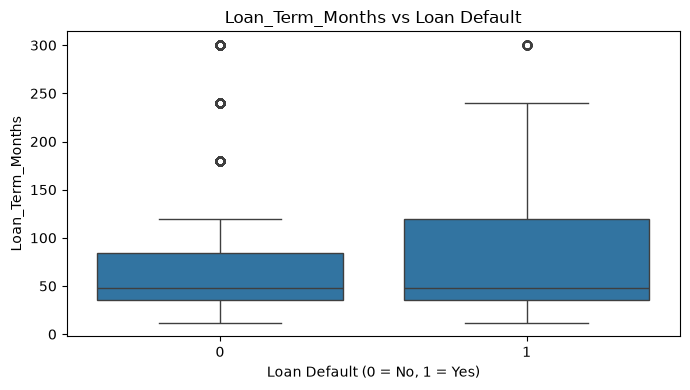

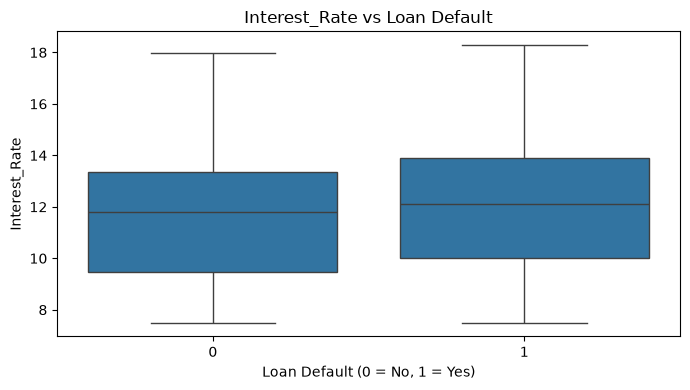

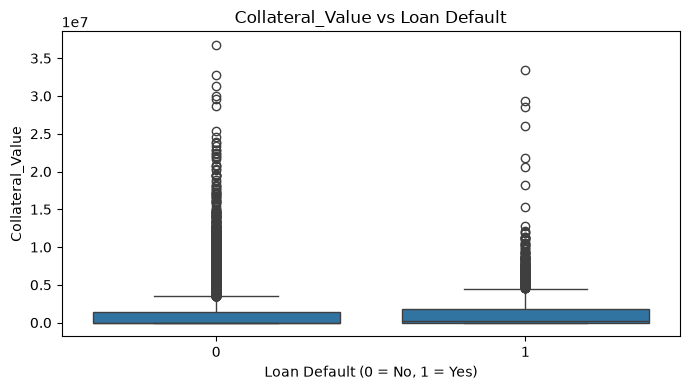

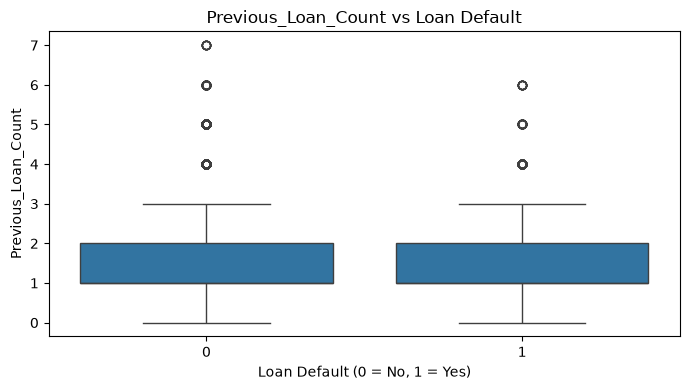

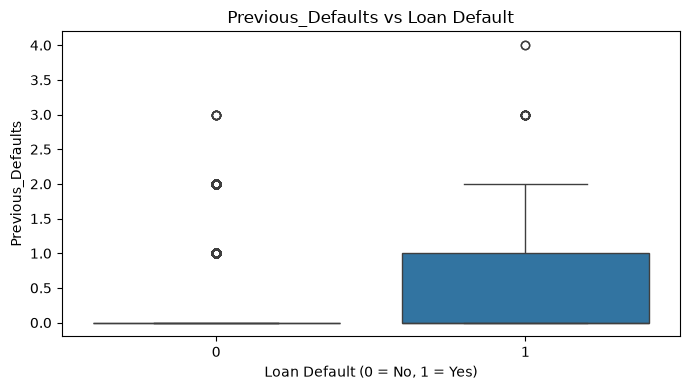

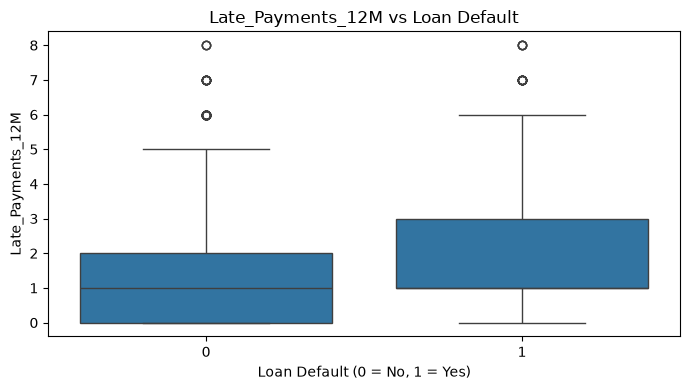

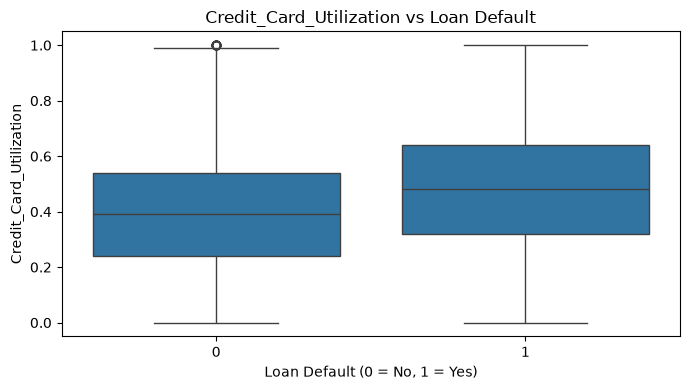

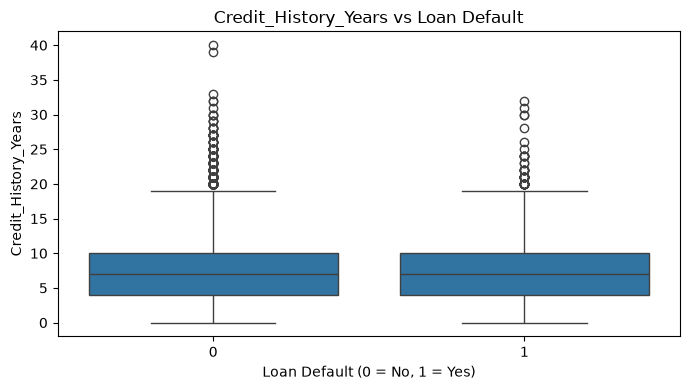

In [20]:

for col in numerical_cols:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x='Loan_Default',
        y=col
    )

    plt.title(f'{col} vs Loan Default')
    plt.xlabel('Loan Default (0 = No, 1 = Yes)')

    plt.tight_layout()
    plt.show()


In [21]:

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Missing Values:")
print(missing_values)

print("\nMissing Value Percentage:")
print((missing_values / len(df)) * 100)


Missing Values:
Savings_Balance            1000
Credit_Score                800
Education                   600
Employment_Years            600
Credit_Card_Utilization     600
Debt_to_Income_Ratio        500
Dependents                  400
Annual_Income               400
Loan_Purpose                400
Collateral_Value            300
dtype: int64

Missing Value Percentage:
Savings_Balance            5.0
Credit_Score               4.0
Education                  3.0
Employment_Years           3.0
Credit_Card_Utilization    3.0
Debt_to_Income_Ratio       2.5
Dependents                 2.0
Annual_Income              2.0
Loan_Purpose               2.0
Collateral_Value           1.5
dtype: float64


In [22]:

corr_matrix = df[numerical_cols].corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = [
    (column, row, upper_triangle.loc[row, column])
    for column in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, column])
    and upper_triangle.loc[row, column] > 0.80
]

print("Highly Correlated Feature Pairs:")

for feature1, feature2, value in high_corr:
    print(f"{feature1} - {feature2}: {value:.2f}")


Highly Correlated Feature Pairs:
Monthly_Income - Annual_Income: 1.00
Existing_EMI - Existing_Loan_Amount: 0.98
Collateral_Value - Loan_Amount: 0.89


In [23]:

X = df.drop(
    columns=['Loan_Default', 'Loan_ID', 'Customer_ID']
)

y = df['Loan_Default']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())


Feature Shape: (20000, 22)
Target Shape: (20000,)

Feature Columns:
['Age', 'Employment_Type', 'Employment_Years', 'Education', 'Dependents', 'Annual_Income', 'Monthly_Income', 'Existing_Loan_Amount', 'Existing_EMI', 'Credit_Score', 'Savings_Balance', 'Debt_to_Income_Ratio', 'Loan_Amount', 'Loan_Term_Months', 'Interest_Rate', 'Loan_Purpose', 'Collateral_Value', 'Previous_Loan_Count', 'Previous_Defaults', 'Late_Payments_12M', 'Credit_Card_Utilization', 'Credit_History_Years']


In [24]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Data: (16000, 22)
Testing Data: (4000, 22)

Training Target Distribution:
Loan_Default
0    86.7875
1    13.2125
Name: proportion, dtype: float64

Testing Target Distribution:
Loan_Default
0    86.775
1    13.225
Name: proportion, dtype: float64


# Logistic Regression

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [26]:
# Separate numerical and categorical features
num_features = X_train.select_dtypes(include=np.number).columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

In [27]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [28]:
# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [29]:
# Combine preprocessing
preprocessor_lr = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

## Build and train Logistic Regression

In [30]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

In [31]:
# Train model
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


## Model predictions

In [33]:

y_pred_lr = lr_pipeline.predict(X_test)

y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]


## Model Evaluation

In [36]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


In [37]:

print("Logistic Regression Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Logistic Regression Performance
Accuracy: 0.73425
Precision: 0.2864
Recall: 0.6767485822306238
F1 Score: 0.4024732996065205
ROC-AUC: 0.7820847758826985

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.74      0.83      3471
           1       0.29      0.68      0.40       529

    accuracy                           0.73      4000
   macro avg       0.61      0.71      0.62      4000
weighted avg       0.85      0.73      0.77      4000



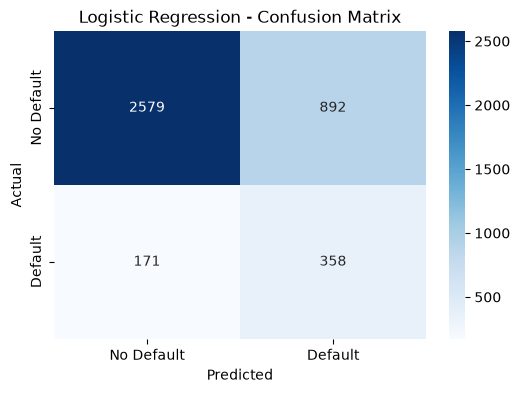

In [82]:

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()


## Hyper parameter tuning

## Define Parameter Grid

In [83]:
param_grid_lr = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2']
}

## Configure GridSearchCV

In [85]:
from sklearn.model_selection import GridSearchCV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_pipeline.set_params(
    classifier__solver='liblinear'
)

grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    scoring='f1',
    cv=cv,
    verbose=1,
    n_jobs=-1
)

## Train

In [86]:
grid_search_lr.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_lr.best_params_)

print("\nBest Cross-Validation F1:")
print(grid_search_lr.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'classifier__C': 0.1, 'classifier__penalty': 'l1'}

Best Cross-Validation F1:
0.40566690938587086


## Evaluate tuned Logistic Regression

In [87]:
best_lr_model = grid_search_lr.best_estimator_

y_pred_lr_tuned = best_lr_model.predict(X_test)

y_prob_lr_tuned = best_lr_model.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression")

print("Accuracy:", accuracy_score(y_test, y_pred_lr_tuned))
print("Precision:", precision_score(y_test, y_pred_lr_tuned))
print("Recall:", recall_score(y_test, y_pred_lr_tuned))
print("F1 Score:", f1_score(y_test, y_pred_lr_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_tuned))

Tuned Logistic Regression
Accuracy: 0.73375
Precision: 0.28525641025641024
Recall: 0.6729678638941399
F1 Score: 0.4006752954417558
ROC-AUC: 0.7822917296377929

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.74      0.83      3471
           1       0.29      0.67      0.40       529

    accuracy                           0.73      4000
   macro avg       0.61      0.71      0.61      4000
weighted avg       0.85      0.73      0.77      4000



# Decision Tree Classifier

In [39]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


## Preprocessing pipeline

In [40]:

# Numerical features
num_pipeline_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical features
cat_pipeline_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor_dt = ColumnTransformer([
    ('num', num_pipeline_dt, num_features),
    ('cat', cat_pipeline_dt, cat_features)
])


## Build and train Decision Tree

In [41]:

dt_pipeline = Pipeline([
    ('preprocessor', preprocessor_dt),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

dt_pipeline.fit(X_train, y_train)

print("Decision Tree training completed!")


Decision Tree training completed!


## Prediction

In [42]:

y_pred_dt = dt_pipeline.predict(X_test)

y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]


## Model evaluation

In [43]:

print("Decision Tree Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Decision Tree Performance
Accuracy: 0.80275
Precision: 0.24806201550387597
Recall: 0.24196597353497165
F1 Score: 0.24497607655502393
ROC-AUC: 0.5650913128982838

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.89      0.89      3471
           1       0.25      0.24      0.24       529

    accuracy                           0.80      4000
   macro avg       0.57      0.57      0.57      4000
weighted avg       0.80      0.80      0.80      4000



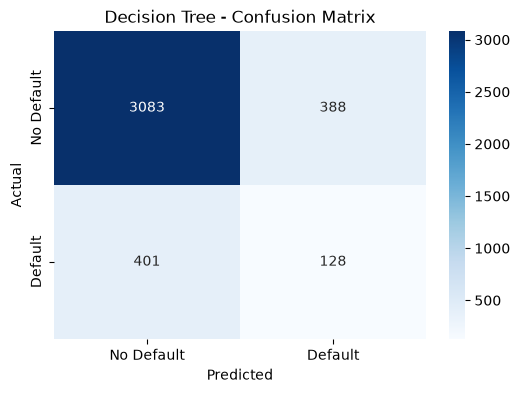

In [44]:

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')

plt.show()


In [88]:
from sklearn.model_selection import RandomizedSearchCV

param_grid_dt = {
    'classifier__max_depth': [None, 5, 10, 15, 20, 30],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 5, 10],
    'classifier__max_features': [None, 'sqrt', 'log2'],
    'classifier__criterion': ['gini', 'entropy']
}

In [89]:
random_search_dt = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=param_grid_dt,
    n_iter=30,
    scoring='f1',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search_dt.fit(X_train, y_train)

print("Best Parameters:", random_search_dt.best_params_)
print("Best CV F1 Score:", random_search_dt.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__criterion': 'gini'}
Best CV F1 Score: 0.36593640163218955


## Evaluate Tuned Decision Tree 

In [90]:
best_dt_model = random_search_dt.best_estimator_

y_pred_dt_tuned = best_dt_model.predict(X_test)
y_prob_dt_tuned = best_dt_model.predict_proba(X_test)[:, 1]

print("Tuned Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_dt_tuned))
print("Precision:", precision_score(y_test, y_pred_dt_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dt_tuned, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_dt_tuned, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_tuned, zero_division=0))

Tuned Decision Tree
Accuracy: 0.7025
Precision: 0.25500370644922166
Recall: 0.6502835538752363
F1 Score: 0.3663471778487753
ROC-AUC: 0.73944195464554

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.71      0.81      3471
           1       0.26      0.65      0.37       529

    accuracy                           0.70      4000
   macro avg       0.59      0.68      0.59      4000
weighted avg       0.84      0.70      0.75      4000



# Random Forest

In [45]:

from sklearn.ensemble import RandomForestClassifier


## Preprocessing pipeline

In [47]:
num_pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_rf = ColumnTransformer([
    ('num', num_pipeline_rf, num_features),
    ('cat', cat_pipeline_rf, cat_features)
])

## Build and train model

In [49]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## Predictions

In [50]:
y_pred_rf = rf_pipeline.predict(X_test)

y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

## Evaluation

In [51]:
print("Random Forest Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
Accuracy: 0.87025
Precision: 0.6041666666666666
Recall: 0.054820415879017016
F1 Score: 0.10051993067590988
ROC-AUC: 0.7569875484639403

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.99      0.93      3471
           1       0.60      0.05      0.10       529

    accuracy                           0.87      4000
   macro avg       0.74      0.52      0.52      4000
weighted avg       0.84      0.87      0.82      4000



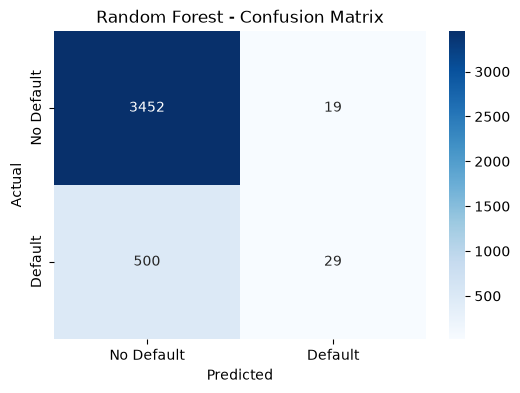

In [52]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')

plt.show()

## Hyper paramter tuning

In [91]:
param_grid_rf = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 2, 5, 10],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__criterion': ['gini', 'entropy']
}

In [92]:
random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid_rf,
    n_iter=30,
    scoring='f1',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search_rf.fit(X_train, y_train)

print("Best Parameters:", random_search_rf.best_params_)
print("Best CV F1 Score:", random_search_rf.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__criterion': 'entropy'}
Best CV F1 Score: 0.41895794748887794


In [93]:
best_rf_model = random_search_rf.best_estimator_

y_pred_rf_tuned = best_rf_model.predict(X_test)
y_prob_rf_tuned = best_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print("Precision:", precision_score(y_test, y_pred_rf_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf_tuned, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf_tuned, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned, zero_division=0))

Tuned Random Forest
Accuracy: 0.80925
Precision: 0.350765306122449
Recall: 0.5198487712665406
F1 Score: 0.4188880426504189
ROC-AUC: 0.760930834421202

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.85      0.89      3471
           1       0.35      0.52      0.42       529

    accuracy                           0.81      4000
   macro avg       0.64      0.69      0.65      4000
weighted avg       0.85      0.81      0.82      4000



# Light GBM

In [53]:
from lightgbm import LGBMClassifier

## Preprocessing pipeline

In [55]:
num_pipeline_lgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline_lgb = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_lgb = ColumnTransformer([
    ('num', num_pipeline_lgb, num_features),
    ('cat', cat_pipeline_lgb, cat_features)
])

## Build and train model

In [56]:
lgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_lgb),
    ('classifier', LGBMClassifier(
        objective='binary',
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lgb_pipeline.fit(X_train, y_train)

print("LightGBM training completed!")

LightGBM training completed!


## Predictions

In [58]:
y_pred_lgb = lgb_pipeline.predict(X_test)

y_prob_lgb = lgb_pipeline.predict_proba(X_test)[:, 1]

## Evaluation

In [59]:
print("LightGBM Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_lgb))
print("Precision:", precision_score(y_test, y_pred_lgb))
print("Recall:", recall_score(y_test, y_pred_lgb))
print("F1 Score:", f1_score(y_test, y_pred_lgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgb))

LightGBM Performance
Accuracy: 0.7725
Precision: 0.3077699293642785
Recall: 0.5765595463137996
F1 Score: 0.40131578947368424
ROC-AUC: 0.7559846396744508

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.80      0.86      3471
           1       0.31      0.58      0.40       529

    accuracy                           0.77      4000
   macro avg       0.62      0.69      0.63      4000
weighted avg       0.84      0.77      0.80      4000



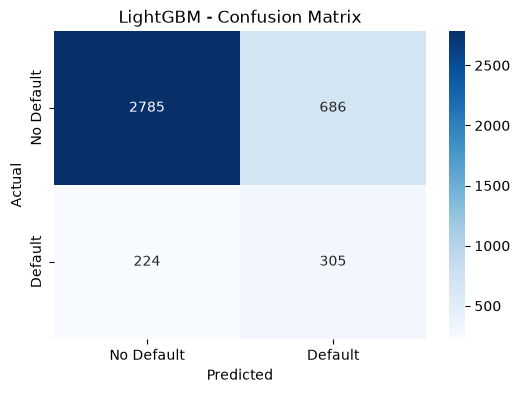

In [60]:
cm_lgb = confusion_matrix(y_test, y_pred_lgb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('LightGBM - Confusion Matrix')

plt.show()

## Hyper parameter tuning

In [61]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

In [62]:
param_grid_lgb = {
    'classifier__n_estimators': [200, 400, 600, 800, 1000],

    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],

    'classifier__num_leaves': [15, 31, 51, 70],

    'classifier__max_depth': [-1, 5, 8, 10, 12],

    'classifier__min_child_samples': [20, 30, 50, 70],

    'classifier__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],

    'classifier__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],

    'classifier__reg_alpha': [0, 0.1, 0.5, 1.0],

    'classifier__reg_lambda': [0, 0.1, 0.5, 1.0, 2.0],

    'classifier__subsample_freq': [1]
}

## Configure Randomized SearchCV

In [63]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search_lgb = RandomizedSearchCV(
    estimator=lgb_pipeline,
    param_distributions=param_grid_lgb,
    n_iter=30,
    scoring='f1',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=1
)

## Train the search

In [64]:
random_search_lgb.fit(X_train, y_train)

print("Best Parameters:")
print(random_search_lgb.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search_lgb.best_score_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


C:\Users\Asus\anaconda3\Lib\site-packages\numpy\ma\core.py:2846: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Best Parameters:
{'classifier__subsample_freq': 1, 'classifier__subsample': 0.7, 'classifier__reg_lambda': 1.0, 'classifier__reg_alpha': 0.1, 'classifier__num_leaves': 51, 'classifier__n_estimators': 600, 'classifier__min_child_samples': 70, 'classifier__max_depth': 12, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.7}

Best Cross-Validation F1 Score:
0.41557500381490303


In [65]:
best_lgb_model = random_search_lgb.best_estimator_

print("Best LightGBM model selected successfully!")

Best LightGBM model selected successfully!


## Best Model Prediction

In [66]:
best_lgb_model = random_search_lgb.best_estimator_

y_pred_lgb_tuned = best_lgb_model.predict(X_test)

y_prob_lgb_tuned = best_lgb_model.predict_proba(X_test)[:, 1]

## Best Model Evaluation

In [68]:
print("Tuned LightGBM Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_lgb_tuned))
print("Precision:", precision_score(y_test, y_pred_lgb_tuned))
print("Recall:", recall_score(y_test, y_pred_lgb_tuned))
print("F1 Score:", f1_score(y_test, y_pred_lgb_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgb_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgb_tuned))

Tuned LightGBM Performance
Accuracy: 0.78225
Precision: 0.32298136645962733
Recall: 0.5897920604914934
F1 Score: 0.41739130434782606
ROC-AUC: 0.7663372289654653

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      3471
           1       0.32      0.59      0.42       529

    accuracy                           0.78      4000
   macro avg       0.63      0.70      0.64      4000
weighted avg       0.85      0.78      0.81      4000



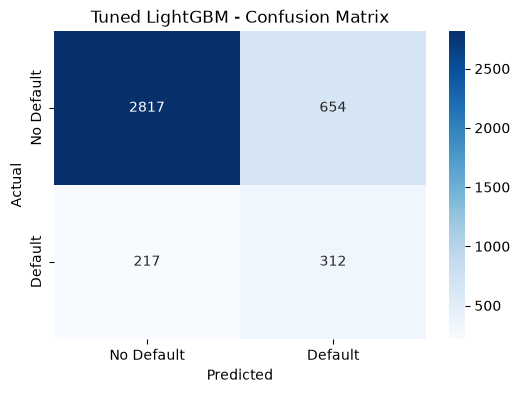

In [69]:
cm_lgb_tuned = confusion_matrix(y_test, y_pred_lgb_tuned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lgb_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned LightGBM - Confusion Matrix')

plt.show()

## Create validation data

In [70]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

## Train a validation model

In [72]:
lgb_validation_model = clone(best_lgb_model)

lgb_validation_model.fit(X_train_sub, y_train_sub)

y_val_prob = lgb_validation_model.predict_proba(X_val)[:, 1]

## find optimal threshold

In [73]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Validation F1 Score:", f1_scores[best_index])
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])

Best Threshold: 0.6833559845302378
Validation F1 Score: 0.4291091592977423
Precision: 0.4572192513368984
Recall: 0.40425531914893614


## Visualize threshold performance

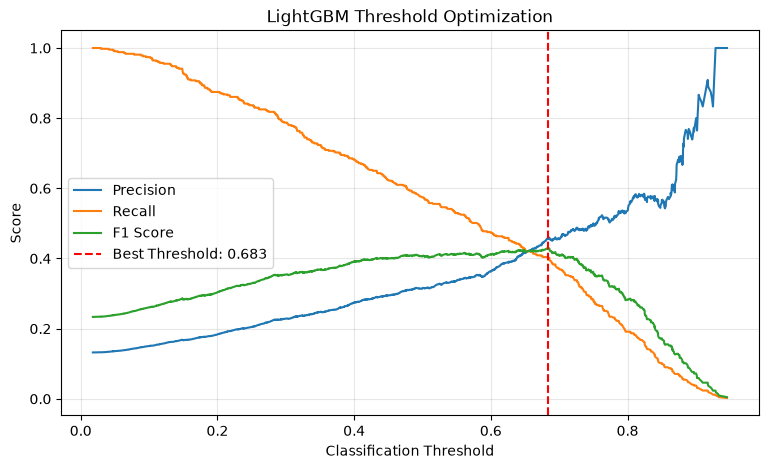

In [74]:
plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.plot(thresholds, f1_scores, label='F1 Score')

plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    label=f'Best Threshold: {best_threshold:.3f}'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('LightGBM Threshold Optimization')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Evaluate on the untouched test set

In [76]:
y_prob_test = best_lgb_model.predict_proba(X_test)[:, 1]

y_pred_lgb_custom = (
    y_prob_test >= best_threshold
).astype(int)

print("LightGBM - Optimized Threshold")

print("Accuracy:", accuracy_score(y_test, y_pred_lgb_custom))
print("Precision:", precision_score(y_test, y_pred_lgb_custom))
print("Recall:", recall_score(y_test, y_pred_lgb_custom))
print("F1 Score:", f1_score(y_test, y_pred_lgb_custom))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lgb_custom))

LightGBM - Optimized Threshold
Accuracy: 0.854
Precision: 0.4406047516198704
Recall: 0.3856332703213611
F1 Score: 0.4112903225806452
ROC-AUC: 0.7663372289654653

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      3471
           1       0.44      0.39      0.41       529

    accuracy                           0.85      4000
   macro avg       0.67      0.66      0.66      4000
weighted avg       0.85      0.85      0.85      4000



In [78]:
import joblib

joblib.dump(best_lgb_model, 'best_lightgbm_model.pkl')

print("LightGBM model saved successfully!")

LightGBM model saved successfully!


In [79]:
loaded_model = joblib.load('best_lightgbm_model.pkl')

test_prediction = loaded_model.predict(X_test)

print("Model loaded successfully!")
print("Predictions:", test_prediction[:10])

Model loaded successfully!
Predictions: [0 0 0 1 0 0 0 0 0 1]


In [94]:
results = [
    ["Logistic Regression", "Baseline", 0.7343, 0.2864, 0.6767, 0.4025, 0.7821],
    ["Logistic Regression", "Tuned",    0.73375, 0.2853, 0.6730, 0.4007, 0.7823],

    ["Decision Tree", "Baseline", 0.8027, 0.2481, 0.2420, 0.2450, 0.5651],
    ["Decision Tree", "Tuned",    0.7025, 0.2550, 0.6503, 0.3663, 0.7394],

    ["Random Forest", "Baseline", 0.8703, 0.6042, 0.0548, 0.1005, 0.7570],
    ["Random Forest", "Tuned",    0.80925, 0.3508, 0.5198, 0.4189, 0.7609],

    ["LightGBM", "Baseline", 0.7725, 0.3078, 0.5766, 0.4013, 0.7560],
    ["LightGBM", "Tuned",    0.7823, 0.3230, 0.5898, 0.4174, 0.7663]
]

results_df = pd.DataFrame(
    results,
    columns=[
        "Model", "Version", "Accuracy", "Precision",
        "Recall", "F1 Score", "ROC-AUC"
    ]
)

results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Version,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,Tuned,0.8092,0.3508,0.5198,0.4189,0.7609
1,LightGBM,Tuned,0.7823,0.3230,0.5898,0.4174,0.7663
2,Logistic Regression,Baseline,0.7343,0.2864,0.6767,0.4025,0.7821
3,LightGBM,Baseline,0.7725,0.3078,0.5766,0.4013,0.7560
4,Logistic Regression,Tuned,0.7338,0.2853,0.6730,0.4007,0.7823
5,Decision Tree,Tuned,0.7025,0.2550,0.6503,0.3663,0.7394
6,Decision Tree,Baseline,0.8027,0.2481,0.2420,0.2450,0.5651
7,Random Forest,Baseline,0.8703,0.6042,0.0548,0.1005,0.7570


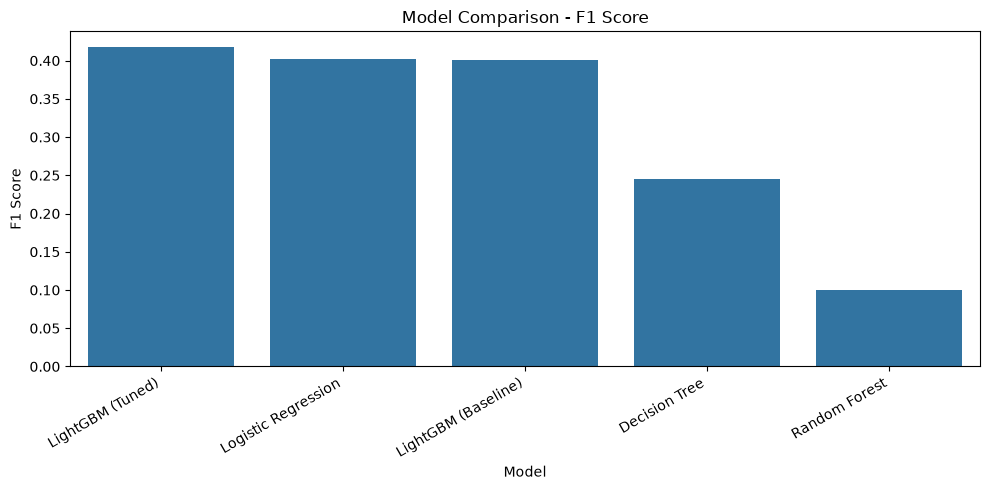

In [81]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x='Model',
    y='F1 Score'
)

plt.title('Model Comparison - F1 Score')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

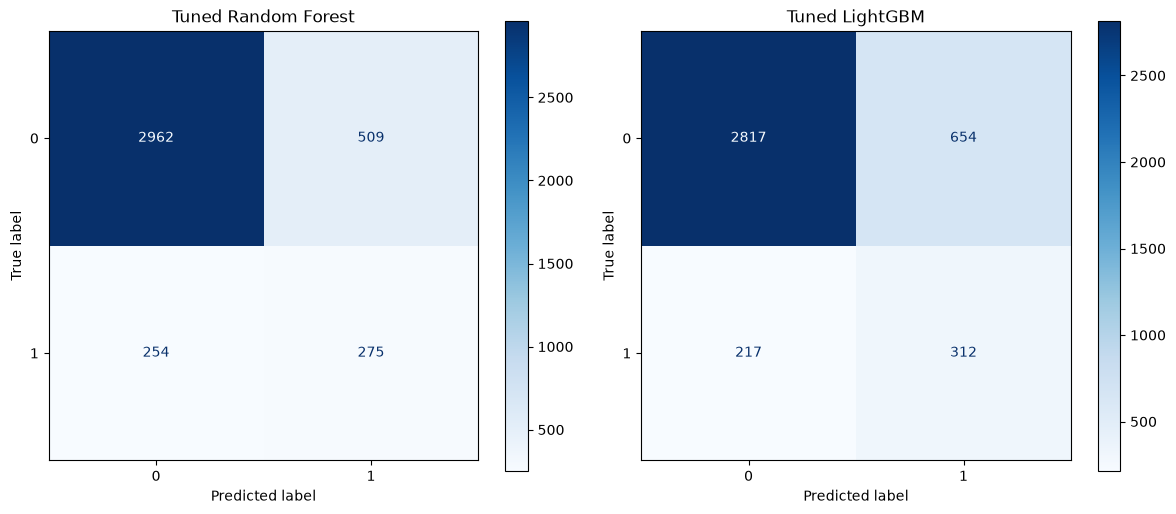

In [95]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_tuned,
    ax=axes[0], cmap='Blues'
)
axes[0].set_title("Tuned Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lgb_tuned,
    ax=axes[1], cmap='Blues'
)
axes[1].set_title("Tuned LightGBM")

plt.tight_layout()
plt.show()

In [96]:
import joblib

best_rf_model = random_search_rf.best_estimator_

joblib.dump(best_rf_model, 'best_random_forest_model.pkl')

print("Random Forest model saved successfully!")


Random Forest model saved successfully!
